# Modules

In [6]:
import sys
import numpy as np      
from skimage.transform import resize
from netCDF4 import Dataset                             
from scipy.ndimage import zoom
from matplotlib.patches import Rectangle                
import cartopy.crs as ccrs                              
import cartopy.feature as cfeature                   
import matplotlib.pyplot as plt                         
plt.style.use('default')                               
plt.rcParams['figure.facecolor'] = 'white'
import warnings
warnings.filterwarnings("ignore")
import cartopy.io.shapereader as shpreader

In [7]:
# load
geodata = np.load("/gws/ssde/j25b/cocoon/SSA_domain/lat_lon_2268_2080.npz")
lons = geodata["lon"][:, :]
lats = geodata["lat"][:, :]

# replace missing values
filtered_lons = np.where(lons == -999.999, np.nan, lons)
filtered_lats = np.where(lats == -999.999, np.nan, lats)

# Core data 

In [8]:
year = "2021"
month = "02"
day = "14"
hour = "12"
minute = "00"

In [9]:
path_core = f'/gws/ssde/j25b/cocoon/SSA_domain/ch9_wavelet/{year}/{month}'

In [10]:
# file of interest at time t0
file = f'{path_core}/{year}{month}{day}{hour}{minute}.nc'

data = Dataset(file, mode='r')

# wavelet power maxima's coordinates
x0_lat = data["max_lat"][:]
x0_lon = data["max_lon"][:]

# cloud top temperature and wavelet power arrays
temp = data["tir"][0, :, :]
cores = data["cores"][0, :, :]
binary_cores = (cores != 0).astype(int)

In [11]:
# Earth radius in km
R = 6371.0

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.deg2rad, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

# choose a representative point near the centre
i = lats.shape[0] // 2
j = lats.shape[1] // 2

# meridional spacing (north–south)
dy = haversine(
    lats[i, j], lons[i, j],
    lats[i+1, j], lons[i+1, j]
)

# zonal spacing (east–west)
dx = haversine(
    lats[i, j], lons[i, j],
    lats[i, j+1], lons[i, j+1]
)

print(f"dy (N–S spacing): {dy:.2f} km")
print(f"dx (E–W spacing): {dx:.2f} km")


dy (N–S spacing): 3.05 km
dx (E–W spacing): 3.09 km


# Plot Dakar Context Domain with Core Data

In [12]:
cores.shape

(2080, 2268)

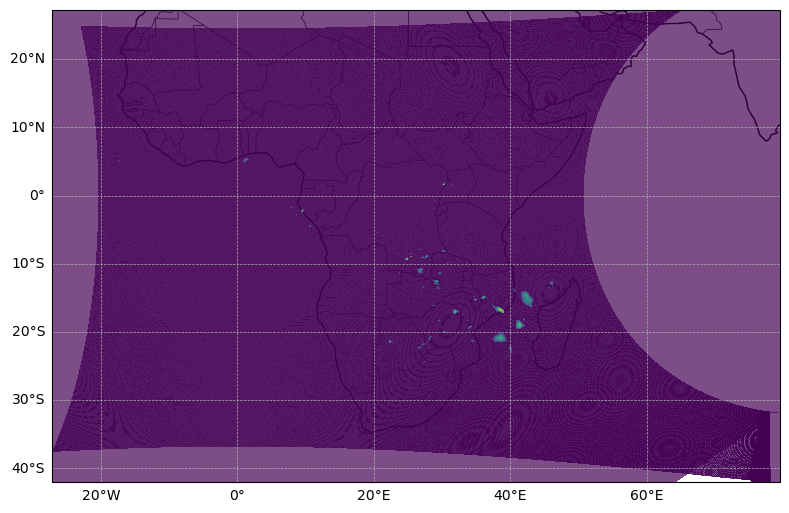

In [13]:
# Create figure and axis
fig = plt.figure(figsize=(8, 10))
ax = plt.axes(projection=ccrs.PlateCarree())

extent = (
    np.nanmin(filtered_lons),
    np.nanmax(filtered_lons),
    np.nanmin(filtered_lats),
    np.nanmax(filtered_lats),    
)

ax.set_extent(extent, crs=ccrs.PlateCarree())


# Base features
ax.add_feature(cfeature.LAND, facecolor='none', edgecolor='black', zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor='none', zorder=0)
ax.add_feature(cfeature.COASTLINE, edgecolor='black', linewidth=0.5, zorder=1)
ax.add_feature(cfeature.BORDERS, edgecolor='black', linewidth=0.5, zorder=1)

# Load Natural Earth country boundaries
shapename = 'admin_0_countries'
countries_shp = shpreader.natural_earth(resolution='10m', category='cultural', name=shapename)

# Gridlines
gl = ax.gridlines(draw_labels=True, alpha=1, linestyle='--', linewidth=0.5)
gl.top_labels = False
gl.right_labels = False

contour_core = ax.pcolormesh(
    lons, lats, cores,
    transform=ccrs.PlateCarree(),
    alpha=0.7,
    zorder=2
)
plt.tight_layout()
plt.show()

In [14]:
import sys

sys.path.insert(1, "/home/users/mendrika/ASNIE/Utilities/Scripts")

from asnie_utils import GeoGrid

In [15]:
extent_grid = (-26, -11, 42, 52)
grid = GeoGrid(lats, lons, *extent_grid)

In [16]:
cores = grid.crop(cores)
lats = np.asarray(grid.crop(lats)) # to remove mask
lons = np.asarray(grid.crop(lons))

np.save("core_lats_mdg.npy", lats)
np.save("core_lons_mdg.npy", lons)

In [17]:
print(grid.y0, grid.y1)
print(grid.x0, grid.x1)

350 844
1935 2258


In [18]:
assert cores.shape == lats.shape == lons.shape

In [19]:
cores.shape

(495, 324)

In [20]:
CONTEXT_LAT_MIN = -28
CONTEXT_LAT_MAX = -10
CONTEXT_LON_MIN = 40
CONTEXT_LON_MAX = 55

extent = (
    CONTEXT_LON_MIN,
    CONTEXT_LON_MAX,
    CONTEXT_LAT_MIN,
    CONTEXT_LAT_MAX,    
)

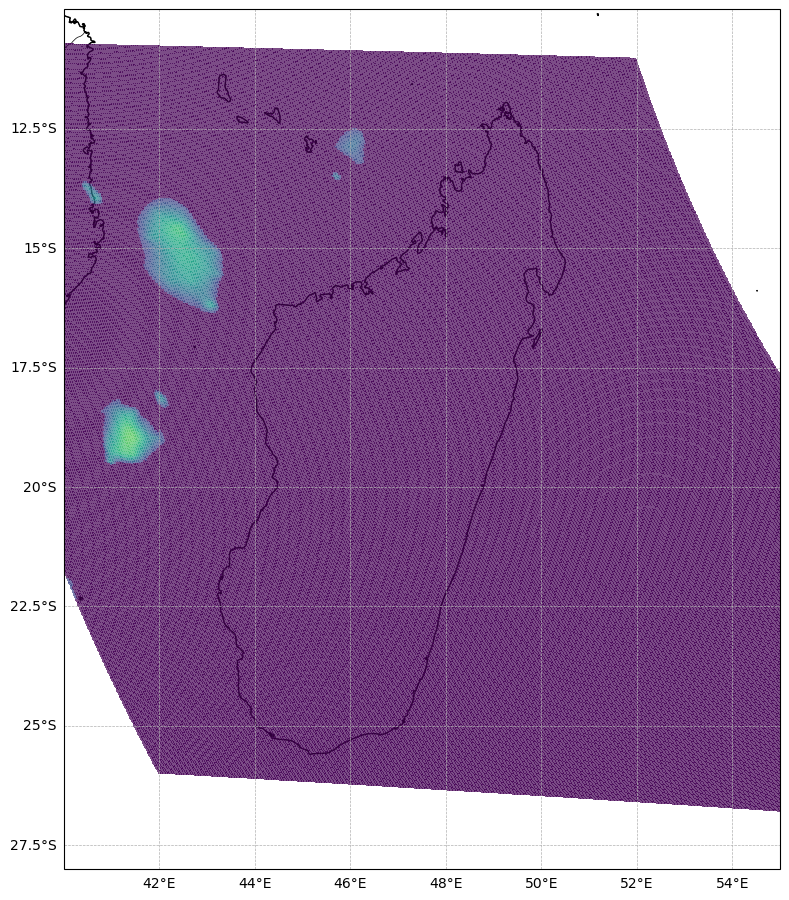

In [21]:
# Create figure and axis
fig = plt.figure(figsize=(8, 10))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent(extent, crs=ccrs.PlateCarree())

# Base features
ax.add_feature(cfeature.LAND, facecolor='none', edgecolor='black', zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor='none', zorder=0)
ax.add_feature(cfeature.COASTLINE, edgecolor='black', linewidth=0.5, zorder=1)
ax.add_feature(cfeature.BORDERS, edgecolor='black', linewidth=0.5, zorder=1)

# Load Natural Earth country boundaries
shapename = 'admin_0_countries'
countries_shp = shpreader.natural_earth(resolution='10m', category='cultural', name=shapename)

# Gridlines
gl = ax.gridlines(draw_labels=True, alpha=1, linestyle='--', linewidth=0.5)
gl.top_labels = False
gl.right_labels = False

contour_core = ax.pcolormesh(
    lons, lats, cores,
    transform=ccrs.PlateCarree(),
    alpha=0.7,
    zorder=2
)

plt.tight_layout()
plt.show()